기준연월,부두,처리TEU,재항시간합계,선박수,평균재항시간,체류생산성
2022-01,1부두,248000,2069.42,71,29.15,119.84
2022-01,2부두,447000,3286.38,143,22.98,136.02
2022-01,3부두,258000,2195.82,75,29.28,117.50
2022-01,4부두,185000,1625.68,53,30.67,113.80
2022-01,5부두,219000,2438.12,77,31.66,89.82
2022-02,1부두,227000,1850.63,57,32.47,122.66
2022-02,2부두,392000,3219.02,133,24.20,121.78
2022-02,3부두,217000,1983.42,72,27.55,109.41
2022-02,4부두,180000,1647.50,47,35.05,109.26
2022-02,5부두,192000,2782.07,62,44.87,69.01


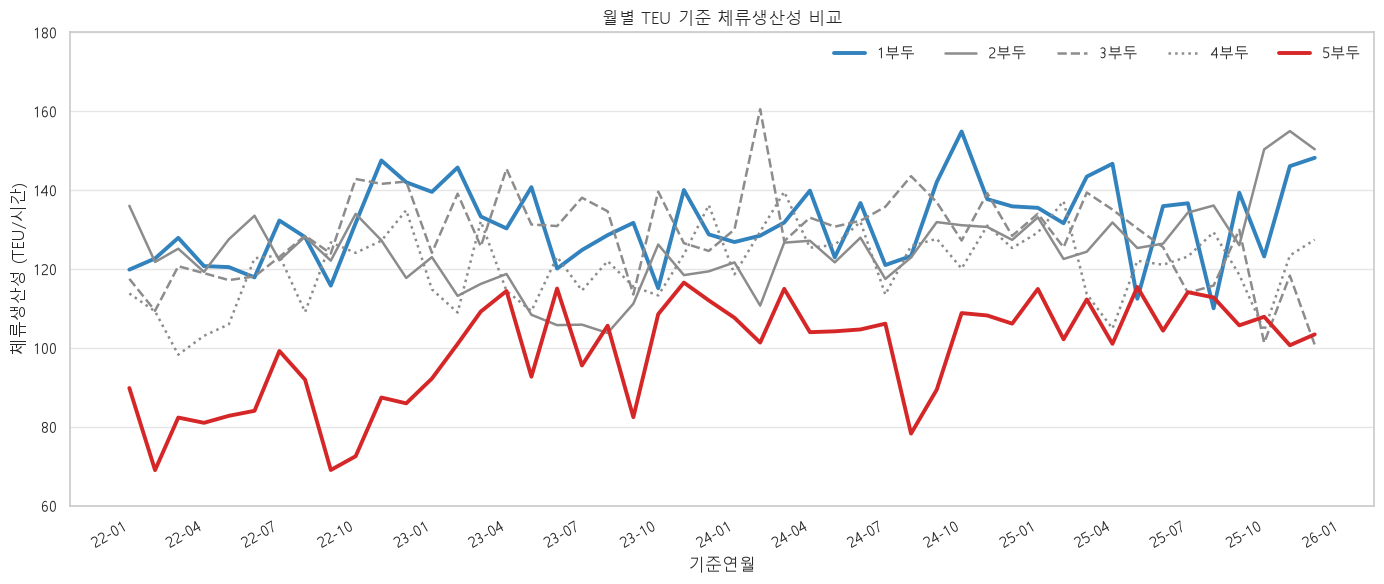

In [4]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path("C:/final")

DATA_PATH = PROJECT_ROOT / "data" / "record.csv"
if not DATA_PATH.exists():
    DATA_PATH = PROJECT_ROOT / "data" / "record.csv"

record = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
port_month = pd.read_csv(
    PROJECT_ROOT / "data" / "port_month.csv",
    encoding="cp949",
)

piers = ["1부두", "2부두", "3부두", "4부두", "5부두"]
port_month.columns = [
    "연도", "월", "1부두", "2부두", "3부두", "4부두", "5부두",
    "6부두", "7부두", "단위",
]

record["입항일시"] = pd.to_datetime(record["입항일시"])
record["재항시간"] = pd.to_numeric(record["재항시간"], errors="coerce")
record["부두"] = record["계선장소"].str.extract(
    r"([1-5])부두", expand=False
).map(lambda pier: f"{pier}부두" if pd.notna(pier) else pd.NA)
record["기준연월"] = record["입항일시"].dt.to_period("M").dt.to_timestamp()

monthly_stay = (
    record.loc[record["부두"].isin(piers)]
    .groupby(["기준연월", "부두"], as_index=False)
    .agg(
        선박수=("재항시간", "count"),
        재항시간합계=("재항시간", "sum"),
        평균재항시간=("재항시간", "mean"),
    )
)

monthly_teu = (
    port_month.loc[
        port_month["연도"].between(2022, 2025),
        ["연도", "월", *piers],
    ]
    .melt(id_vars=["연도", "월"], var_name="부두", value_name="처리TEU")
)
monthly_teu["기준연월"] = pd.to_datetime(
    monthly_teu["연도"].astype(str)
    + "-"
    + monthly_teu["월"].astype(str)
    + "-01"
)
monthly_teu["처리TEU"] = monthly_teu["처리TEU"] * 1000
monthly_teu = monthly_teu[["기준연월", "부두", "처리TEU"]]

monthly_productivity = monthly_teu.merge(
    monthly_stay,
    on=["기준연월", "부두"],
    how="left",
)
monthly_productivity["체류생산성"] = (
    monthly_productivity["처리TEU"]
    / monthly_productivity["재항시간합계"]
)
monthly_productivity = monthly_productivity.sort_values(["기준연월", "부두"])

monthly_table = monthly_productivity[
    ["기준연월", "부두", "처리TEU", "재항시간합계", "선박수", "평균재항시간", "체류생산성"]
].copy()
monthly_table["기준연월"] = monthly_table["기준연월"].dt.strftime("%Y-%m")
display(monthly_table.style.format(precision=2).hide(axis="index"))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(14, 6))
colors = {
    "1부두": "#3182bd",
    "2부두": "#8c8c8c",
    "3부두": "#8c8c8c",
    "4부두": "#8c8c8c",
    "5부두": "#d62728",
}
linestyles = {
    "1부두": "-",
    "2부두": "-",
    "3부두": "--",
    "4부두": ":",
    "5부두": "-",
}

for pier in piers:
    pier_data = monthly_productivity[monthly_productivity["부두"] == pier]
    ax.plot(
        pier_data["기준연월"],
        pier_data["체류생산성"],
        label=pier,
        color=colors[pier],
        linestyle=linestyles[pier],
        linewidth=2.8 if pier in ["1부두", "5부두"] else 1.8,
    )

ax.set_title("월별 TEU 기준 체류생산성 비교")
ax.set_xlabel("기준연월")
ax.set_ylabel("체류생산성 (TEU/시간)")
ax.set_ylim(60, 180)
ax.set_yticks(range(60, 181, 20))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
